# SMS Spam Detection with TF-IDF
### Text cleanup, class balance, and model evaluation

This dataset is the classic SMS spam collection (the local CSV columns are `v1` label and `v2` message). We compare Multinomial Naive Bayes with Logistic Regression. A stratified holdout preserves the class ratio. Spam recall matters because a false negative is spam that reaches the user; precision matters too because a false positive hides a legitimate message.

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import re, string
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
sns.set_theme(style='whitegrid',palette='colorblind')

Shape: (5169, 2)
Nulls:
label      0
message    0
dtype: int64
Dtypes:
label      str
message    str
dtype: object


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


,count,percent
label,,
ham,4516,87.37
spam,653,12.63


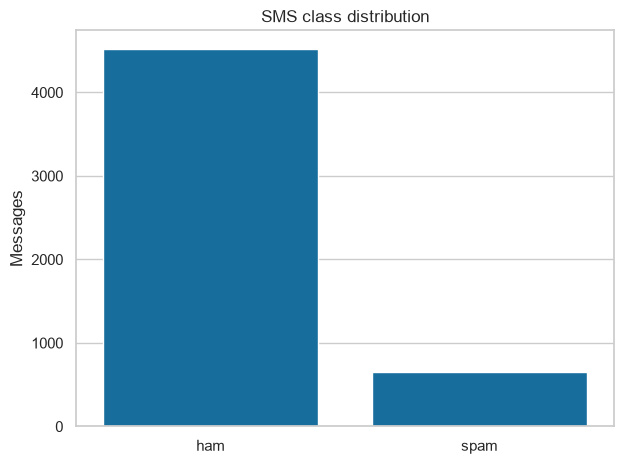

In [2]:
df=pd.read_csv(Path('.')/'spam.csv',encoding='latin-1')
df=df.rename(columns={'v1':'label','v2':'message'})[['label','message']].dropna()
df['label']=df.label.astype(str).str.strip().str.lower()
df['message']=df.message.astype(str)
df=df[df.label.isin(['ham','spam'])].drop_duplicates().reset_index(drop=True)
print('Shape:',df.shape)
print('Nulls:')
print(df.isna().sum())
print('Dtypes:')
print(df.dtypes)
display(df.head())
counts=df.label.value_counts()
summary=pd.DataFrame({'count':counts,'percent':(counts/len(df)*100).round(2)})
display(summary)
sns.barplot(x=summary.index,y=summary['count'])
plt.title('SMS class distribution'); plt.ylabel('Messages'); plt.xlabel('')
plt.tight_layout(); plt.show()

### Preprocessing and TF-IDF
We lowercase text, replace punctuation with spaces, remove English stopwords, and collapse whitespace. This keeps digits and word tokens, which can carry useful signals in SMS messages. TF-IDF represents each message by term frequency weighted down for terms common across many messages, emphasizing terms that are more distinctive to a message. The vectorizer is fit inside each model pipeline, so vocabulary is learned only from the training split.

In [3]:
def clean_text(text):
    text=text.lower()
    text=text.translate(str.maketrans({ch:' ' for ch in string.punctuation}))
    tokens=[w for w in re.findall(r'\b\w+\b',text) if w not in ENGLISH_STOP_WORDS]
    return ' '.join(tokens)
df['clean_message']=df.message.map(clean_text)
display(df[['message','clean_message','label']].head(8))
X_train,X_test,y_train,y_test=train_test_split(df['clean_message'],df['label'],test_size=.2,random_state=42,stratify=df['label'])

,message,clean_message,label
0,"Go until jurong point, crazy.. Available only ...",jurong point crazy available bugis n great wor...,ham
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry 2 wkly comp win fa cup final tkts 2...,spam
3,U dun say so early hor... U c already then say...,u dun say early hor u c say,ham
4,"Nah I don't think he goes to usf, he lives aro...",nah don t think goes usf lives,ham
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling s 3 week s word d like fun...,spam
6,Even my brother is not like to speak with me. ...,brother like speak treat like aids patent,ham
7,As per your request 'Melle Melle (Oru Minnamin...,request melle melle oru minnaminunginte nurung...,ham


In [4]:
models={
    'Multinomial Naive Bayes':Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,sublinear_tf=True)),('clf',MultinomialNB())]),
    'Logistic Regression':Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,sublinear_tf=True)),('clf',LogisticRegression(max_iter=1000,class_weight='balanced',random_state=42))])
}
rows=[]; fitted={}
for name,model in models.items():
    model.fit(X_train,y_train); fitted[name]=model; pred=model.predict(X_test)
    rows.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Spam precision':precision_score(y_test,pred,pos_label='spam'),'Spam recall':recall_score(y_test,pred,pos_label='spam'),'Spam F1':f1_score(y_test,pred,pos_label='spam')})
results=pd.DataFrame(rows).sort_values('Spam F1',ascending=False)
display(results.round(3))
best_name=results.iloc[0]['Model']; best=fitted[best_name]; prediction=best.predict(X_test)
print('Selected by spam F1:',best_name)
print(classification_report(y_test,prediction,labels=['ham','spam'],zero_division=0))

,Model,Accuracy,Spam precision,Spam recall,Spam F1
1,Logistic Regression,0.977,0.928,0.885,0.906
0,Multinomial Naive Bayes,0.968,1.000,0.748,0.856


Selected by spam F1: Logistic Regression
              precision    recall  f1-score   support

         ham       0.98      0.99      0.99       903
        spam       0.93      0.89      0.91       131

    accuracy                           0.98      1034
   macro avg       0.96      0.94      0.95      1034
weighted avg       0.98      0.98      0.98      1034



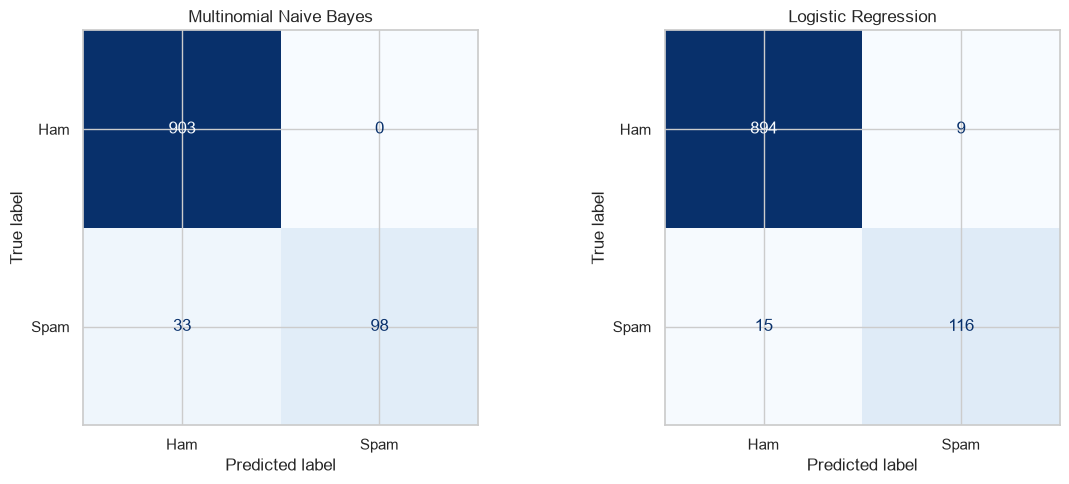

In [5]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,(name,model) in zip(axes,fitted.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,model.predict(X_test),labels=['ham','spam'],display_labels=['Ham','Spam'],cmap='Blues',colorbar=False,ax=ax)
    ax.set_title(name)
plt.tight_layout(); plt.show()

## Interpretation
Compare spam recall and precision in the metric table. Recall is especially important when missed spam can expose users to scams, phishing, or unwanted content. A classifier that flags too many ham messages creates a different cost: users may miss legitimate communication. The preferred threshold depends on that tradeoff; the reported default threshold is a baseline. This is an SMS dataset, so performance may differ on modern email or messages from another population.